# Identificação do projeto

**Título do projeto:** Variação do preço dos combustíveis nos postos brasileiros

**Integrantes do grupo:** Eduardo Pereira, Patrick de Oliveira, Roberto Zhou, Matheus Fraiz de Camargo Antonello

**Turma:** 6º GCL1 — Sistemas de Informação (Noite) — 2026/2

**Descrição breve do problema ou contexto:** o mesmo combustível, no mesmo dia, custa valores diferentes de um posto para outro, inclusive dentro da mesma cidade. Usamos o Levantamento de Preços de Combustíveis da ANP para entender quais fatores estão associados a essa variação.

Este notebook contém o RA3. O RA1 e o RA2 estão em `PJBL_precos_combustiveis.ipynb`.

---

# RA3 — Analysis, Visualization and Machine Learning

Nesta etapa usamos a base preparada no RA1 para produzir análises estatísticas, visualizações e interpretações que ajudem a responder ao problema do projeto, além de uma aplicação simples de Machine Learning.

**Pergunta central:** quais fatores estão associados à variação do preço dos combustíveis entre os postos brasileiros?

## Preparação

A base é a saída do RA1 (`data/processed/precos_combustiveis.parquet`): uma linha por posto, produto e dia, já limpa e validada. No Colab, o arquivo é baixado do repositório.

In [1]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", palette="deep")

ARQUIVO = "data/processed/precos_combustiveis.parquet"
URL = "https://raw.githubusercontent.com/EduardoPereirabsi/PJBL01-Precos-combustiveis/main/" + ARQUIVO

if not os.path.exists(ARQUIVO):
    os.makedirs("data/processed", exist_ok=True)
    resposta = requests.get(URL, timeout=120)
    resposta.raise_for_status()
    with open(ARQUIVO, "wb") as arquivo:
        arquivo.write(resposta.content)

df = pd.read_parquet(ARQUIVO)

print(f"✓ Base carregada: {len(df):,} linhas × {df.shape[1]} colunas")
print(f"Período: {df['data_coleta'].min():%d/%m/%Y} a {df['data_coleta'].max():%d/%m/%Y}")
print("Produtos:", ", ".join(sorted(df["produto"].unique())))
display(df.head(3))

✓ Base carregada: 3,715,016 linhas × 10 colunas
Período: 02/01/2023 a 31/08/2026
Produtos: DIESEL, DIESEL S10, ETANOL, GASOLINA, GASOLINA ADITIVADA, GLP, GNV


,regiao,uf,municipio,cnpj,cep,produto,data_coleta,valor_venda,unidade_medida,bandeira
0,NE,AL,ARAPIRACA,02817655000182,57308-000,ETANOL,2023-01-02,3.89,R$ / litro,VIBRA
1,NE,AL,ARAPIRACA,02817655000182,57308-000,GASOLINA ADITIVADA,2023-01-02,5.14,R$ / litro,VIBRA
2,NE,AL,ARAPIRACA,02817655000182,57308-000,GASOLINA,2023-01-02,5.14,R$ / litro,VIBRA


## 1. Análise estatística descritiva

Realize uma análise estatística dos dados, contemplando:

- **Tendência central:** média e/ou mediana para compreender valores representativos.
- **Dispersão:** amplitude ou desvio-padrão para analisar a variabilidade.
- **Distribuição:** frequência, concentração ou distribuição dos valores.

Apresente os resultados e explique o que eles representam no contexto do projeto.

In [2]:
# Utilize quantas células de código forem necessárias para esta etapa.

**Resposta do grupo:**

[Preencha aqui.]

## 2. Visualização e interpretação dos dados

Produza pelo menos três visualizações que ajudem a compreender diferentes características dos dados. Cada visualização deve ter variáveis e resultados identificados e uma breve interpretação: padrões, tendências, diferenças ou comportamentos relevantes.

In [3]:
# Utilize quantas células de código forem necessárias para esta etapa.

**Resposta do grupo:**

[Preencha aqui.]

## 3. Amostragem e representatividade

Analise brevemente:

- a origem e a abrangência do conjunto de dados;
- se os registros representam adequadamente o problema investigado;
- possíveis limitações ou vieses que possam influenciar os resultados.

In [4]:
# Utilize quantas células de código forem necessárias para esta etapa.

**Resposta do grupo:**

[Preencha aqui.]

## 4. Aplicação de Machine Learning

Aplicação simples de aprendizagem supervisionada, com:

1. definição do problema preditivo;
2. variável-alvo (*target*) e características (*features*);
3. separação dos dados em treino e teste;
4. treinamento de um modelo e previsões;
5. avaliação com pelo menos uma métrica adequada.

**Resposta do grupo:**

**Problema preditivo (regressão):** estimar o preço da gasolina comum em um posto, em R\$/litro, a partir do estado, da bandeira e do mês da coleta. Além de prever, o modelo mostra quanto do preço esses fatores explicam e quanto sobra para a diferença entre postos, que é a pergunta central do projeto.

- **Target:** `valor_venda` da gasolina comum.
- **Features:** `uf` (estado), `bandeira_grupo` (as 5 bandeiras com mais coletas e `OUTRAS`) e `meses` (meses desde janeiro/2023, para captar a tendência no tempo).

Usamos só a gasolina comum porque cada produto tem um nível de preço diferente e o GLP e o GNV nem estão em litro (RA1).

In [5]:
gasolina = df[df["produto"] == "GASOLINA"].copy()

principais = gasolina["bandeira"].value_counts().head(5).index
gasolina["bandeira_grupo"] = gasolina["bandeira"].where(gasolina["bandeira"].isin(principais), "OUTRAS")
gasolina["meses"] = (gasolina["data_coleta"].dt.year - 2023) * 12 + gasolina["data_coleta"].dt.month - 1

# Estado e bandeira viram colunas 0/1; SP e BRANCA ficam como referência
X = pd.get_dummies(gasolina[["uf", "bandeira_grupo"]].astype(str), dtype="int8")
X = X.drop(columns=["uf_SP", "bandeira_grupo_BRANCA"])
X["meses"] = gasolina["meses"].values
y = gasolina["valor_venda"]

print(f"Registros de gasolina comum: {len(X):,}")
print(f"Features: {X.shape[1]} colunas (26 estados + 5 bandeiras + meses)")
print("Bandeiras com mais coletas:", ", ".join(principais))

Registros de gasolina comum: 808,704
Features: 32 colunas (26 estados + 5 bandeiras + meses)
Bandeiras com mais coletas: BRANCA, VIBRA, IPIRANGA, RAIZEN, ALE


**Separação em treino e teste:** a divisão é pelo tempo. O modelo aprende com 2023 a 2025 e é avaliado em janeiro a agosto de 2026, meses que ele nunca viu, como se estivesse prevendo o futuro. Uma divisão aleatória colocaria o mesmo posto, no mesmo mês, no treino e no teste, e o resultado ficaria otimista.

In [6]:
treino = gasolina["data_coleta"] < "2026-01-01"

X_treino, X_teste = X[treino], X[~treino]
y_treino, y_teste = y[treino], y[~treino]

print(f"Treino (2023 a 2025):  {len(X_treino):,} registros ({treino.mean():.0%})")
print(f"Teste  (jan-ago/2026): {len(X_teste):,} registros ({(~treino).mean():.0%})")

Treino (2023 a 2025):  677,508 registros (84%)
Teste  (jan-ago/2026): 131,196 registros (16%)


**Treinamento e avaliação:** usamos uma **regressão linear**. Para saber se o modelo é útil, comparamos com uma referência simples: repetir, para 2026, o preço médio de cada estado em dezembro/2025, o último mês do treino.

A métrica principal é o **MAE** (erro absoluto médio), que fica na mesma unidade do preço: quantos centavos por litro o modelo erra, em média. O **R²** mostra quanto da variação dos preços o modelo explica (1 = tudo, 0 = nada).

In [7]:
media_dez_2025 = gasolina[treino & (gasolina["data_coleta"] >= "2025-12-01")].groupby("uf")["valor_venda"].mean()
previsao_referencia = gasolina.loc[~treino, "uf"].map(media_dez_2025)

regressao = LinearRegression()
regressao.fit(X_treino, y_treino)
previsao_regressao = regressao.predict(X_teste)

resultados = pd.DataFrame({
    "modelo": ["Referência: média do estado em dez/2025", "Regressão linear"],
    "MAE (R$/litro)": [mean_absolute_error(y_teste, previsao_referencia), mean_absolute_error(y_teste, previsao_regressao)],
    "R²": [r2_score(y_teste, previsao_referencia), r2_score(y_teste, previsao_regressao)],
})
print("AVALIAÇÃO NO TESTE (jan-ago/2026)")
print("─" * 50)
display(resultados.style.format({"MAE (R$/litro)": "{:.2f}", "R²": "{:.2f}"}).hide(axis="index"))

AVALIAÇÃO NO TESTE (jan-ago/2026)
──────────────────────────────────────────────────


modelo,MAE (R$/litro),R²
Referência: média do estado em dez/2025,0.41,-0.48
Regressão linear,0.28,0.28


In [8]:
coeficientes = pd.Series(regressao.coef_, index=X.columns)
bandeiras = (coeficientes.filter(like="bandeira_grupo_")
             .rename(lambda nome: nome.replace("bandeira_grupo_", ""))
             .sort_values(ascending=False))

print("Diferença em relação a um posto de bandeira BRANCA, no mesmo estado e mês:")
for nome, valor in bandeiras.items():
    print(f"   {nome:<10} {valor:+.2f} R$/litro")
print(f"\nTendência no tempo: {coeficientes['meses']:+.3f} R$/litro por mês ({coeficientes['meses'] * 12:+.2f} por ano)")

Diferença em relação a um posto de bandeira BRANCA, no mesmo estado e mês:
   VIBRA      +0.18 R$/litro
   IPIRANGA   +0.17 R$/litro
   RAIZEN     +0.15 R$/litro
   ALE        +0.11 R$/litro
   OUTRAS     +0.09 R$/litro

Tendência no tempo: +0.030 R$/litro por mês (+0.36 por ano)


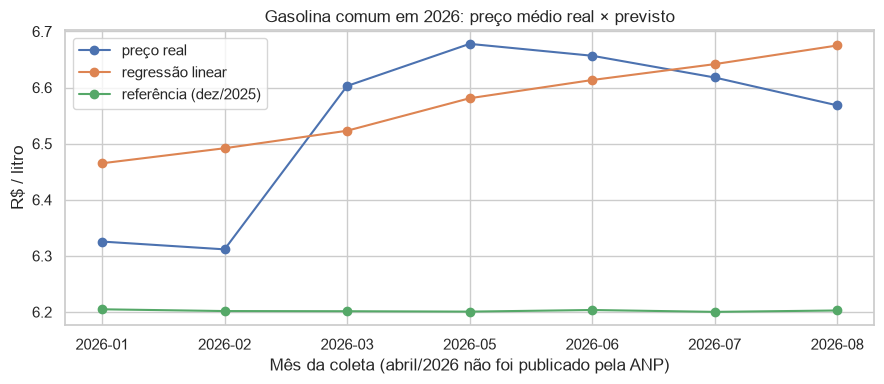

In [9]:
comparacao = pd.DataFrame({
    "mes": gasolina.loc[~treino, "data_coleta"].dt.strftime("%Y-%m").values,
    "preço real": y_teste.values,
    "regressão linear": previsao_regressao,
    "referência (dez/2025)": previsao_referencia.values,
}).groupby("mes").mean()

ax = comparacao.plot(marker="o", figsize=(9, 4))
ax.set_title("Gasolina comum em 2026: preço médio real × previsto")
ax.set_xlabel("Mês da coleta (abril/2026 não foi publicado pela ANP)")
ax.set_ylabel("R$ / litro")
plt.tight_layout()
plt.show()

**Resposta do grupo:**

- **Desempenho:** a regressão linear erra, em média, **R\$ 0,28 por litro** nos meses de 2026, contra R\$ 0,41 da referência que repete o preço de dezembro/2025. O modelo acerta o nível de preço de cada estado e a tendência de alta, que a referência não acompanha.
- **O que o modelo não explica:** o R² de 0,28 mostra que estado, bandeira e mês explicam só uma parte da variação. O resto está em fatores que não existem na base, como a concorrência no bairro, o custo de cada posto e promoções. Isso conversa com a pergunta central: estado e bandeira importam, mas não explicam tudo.
- **Bandeira (pergunta 2):** no mesmo estado e mês, postos com bandeira cobram de **R\$ 0,09 a R\$ 0,18 a mais** por litro que postos de bandeira branca. É uma associação, não uma causa.
- **Limitações:** o modelo segue uma tendência em linha reta. Em janeiro e fevereiro ele previu um preço mais alto que o real, em março o preço deu um salto que a linha reta não acompanha e, de junho a agosto, o preço começou a cair enquanto o modelo continuou subindo. Mudanças bruscas, como alteração de imposto ou de preço nas refinarias, não estão entre as features.

## 5. Conclusões

Apresente uma conclusão geral do RA3, contemplando:

- os principais resultados das análises estatísticas e das visualizações;
- a interpretação do desempenho do modelo de Machine Learning;
- as limitações dos dados e das análises;
- a relação dos resultados com o problema definido no projeto.

**Resposta do grupo:**

[Preencha aqui.]